# Step 3: Evaluate the models properly

In Step 2 we compared models by **accuracy** and saw that a useless "always no" model already scores about 67%.
In this notebook we learn the tools professionals use instead:

1. The **confusion matrix**: the four kinds of right and wrong answers
2. **Precision, recall and F1** for each label
3. **Thresholds**: turning probabilities into yes/no, and picking a better cut-off than 0.5
4. **Multi-label** scores that look at both labels at once
5. A **harder test set** that's closer to real seller mistakes. This is where the surprises are.
6. **Grad-CAM**: where in the photo did the model look?

## 1. Setup

In [1]:
import os, sys, json
if 'google.colab' in sys.modules:
    !git clone -q https://github.com/sujatab1706-tech/my-project.git
    %cd my-project
    !apt-get -qq install -y tesseract-ocr > /dev/null
else:
    os.chdir('..')
!pip install -q -r requirements.txt
sys.path.insert(0, 'src')

Colab forgets files after a restart. If the Step 1 data or Step 2 models are missing, this rebuilds them (about 25 minutes with a GPU).

In [2]:
if not os.path.exists('data/processed/labels.csv'):
    !python src/download_abo.py --n 2000 --listing-files 4 --out data/raw
    !python src/make_violations.py --raw data/raw --out data/processed
if not os.path.exists('results/cnn_mobilenet_predictions.csv'):
    !python src/baselines.py --data data/processed --out results
    !python src/train_cnn.py --model small --epochs 15 --data data/processed --out results
    !python src/train_cnn.py --model mobilenet --epochs 10 --data data/processed --out results

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve
from evaluate import report, multilabel_summary, choose_threshold, label_metrics

pd.set_option('display.width', 140)
COLS = ['accuracy', 'precision', 'recall', 'f1', 'TP', 'FP', 'FN', 'TN']

base = pd.read_csv('results/baseline_predictions.csv')
small = pd.read_csv('results/cnn_small_predictions.csv')
mob = pd.read_csv('results/cnn_mobilenet_predictions.csv')
PROB = {'tlgw': 'tlgw_prob', 'nwb': 'nwb_prob'}     # CNN probability columns
SCORE = {'tlgw': 'tlgw_score', 'nwb': 'nwb_score'}  # baseline score columns
val, test = mob[mob.split == 'val'], mob[mob.split == 'test']

## 2. The confusion matrix
For one label, every image ends up in one of four boxes:

|  | model says **no** | model says **yes** |
|---|---|---|
| truly **fine** | ✅ True Negative (TN) | ❌ False Positive (FP): a *false alarm* |
| truly **broken** | ❌ False Negative (FN): a *miss* | ✅ True Positive (TP): *caught it* |

Here they are for MobileNetV2 on the test set, using the default threshold of 0.5:

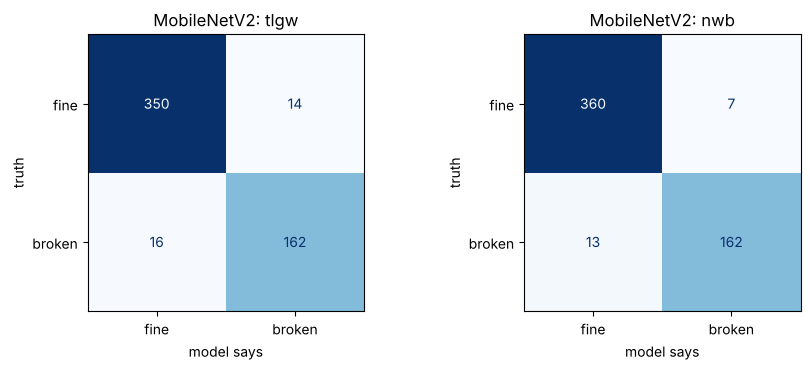

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, label in zip(axes, ['tlgw', 'nwb']):
    cm = confusion_matrix(test[label], test[f'{label}_prob'] >= 0.5)
    ConfusionMatrixDisplay(cm, display_labels=['fine', 'broken']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'MobileNetV2: {label}'); ax.set_xlabel('model says'); ax.set_ylabel('truth')
plt.tight_layout(); plt.show()

## 3. Precision, recall, F1
From those four boxes:
- **Precision** = TP / (TP + FP): *"When it flags an image, how often is it right?"* Low precision means lots of false alarms, so sellers get annoyed and reviewers waste time.
- **Recall** = TP / (TP + FN): *"Of all the broken images, how many did it catch?"* Low recall means bad images slip through onto Amazon.
- **F1** = 2 × P × R / (P + R): one number that is only high when **both** are high.

The "always no" model has recall **0**: it catches nothing. Accuracy hid that; recall exposes it immediately.

In [5]:
rows = []
for name, df, cols in [('Rule / OCR', base, SCORE), ('Small CNN', small, PROB), ('MobileNetV2', mob, PROB)]:
    r = report(df[df.split == 'test'], cols)[COLS]
    r.insert(0, 'model', name)
    rows.append(r)
pd.concat(rows).reset_index().set_index(['label', 'model']).sort_index()

accuracy  precision  recall     f1   TP  FP   FN   TN
label model                                                             
nwb   MobileNetV2     0.963      0.959   0.926  0.942  162   7   13  360
      Rule / OCR      0.987      0.962   1.000  0.980  175   7    0  360
      Small CNN       0.974      0.960   0.960  0.960  168   7    7  360
tlgw  MobileNetV2     0.945      0.920   0.910  0.915  162  14   16  350
      Rule / OCR      0.677      0.508   0.511  0.510   91  88   87  276
      Small CNN       0.662      0.477   0.287  0.358   51  56  127  308

Things to notice:
- **TLGW:** OCR has precision and recall around 0.5, barely better than guessing. The small CNN is worse: it catches fewer than a third of the overlays (low recall). MobileNetV2 is above 0.9 on both.
- Recall also shows *why* the small CNN looked "okay" on accuracy: it mostly says "no", which the many clean images reward.
- **NWB:** the rule has recall **1.0** (it misses nothing) with a few false alarms, which come from banners and watermarks that touch the edge.

## 4. Choosing a threshold
The CNN outputs a probability, and we've been saying "yes" when it's 0.5 or more. But 0.5 is just a habit, not a rule.
- **Lower** the threshold: more images get flagged, so recall goes up and precision goes down.
- **Raise** it: fewer flags, so precision goes up and recall goes down.

⚠️ We choose the threshold on the **validation** set, then check it **once** on the test set.
Tuning on the test set is cheating: the score would look better than it will be on new images.

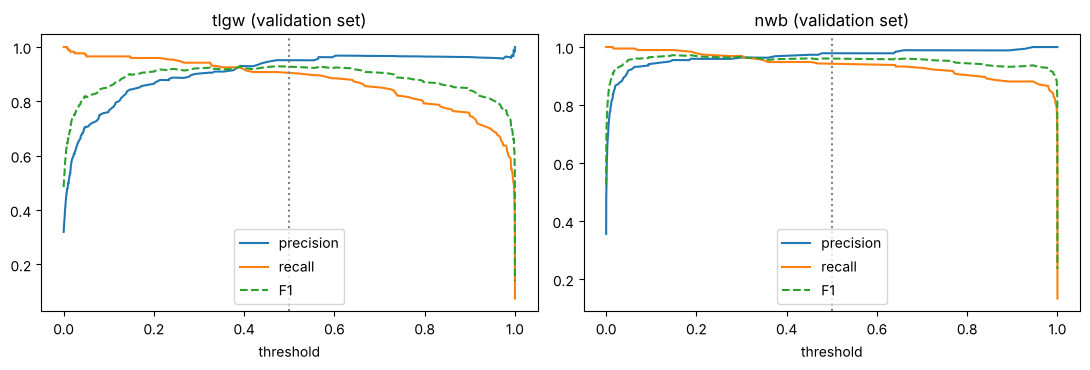

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, label in zip(axes, ['tlgw', 'nwb']):
    p, r, t = precision_recall_curve(val[label], val[f'{label}_prob'])
    ax.plot(t, p[:-1], label='precision'); ax.plot(t, r[:-1], label='recall')
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    ax.plot(t, f1, '--', label='F1')
    ax.axvline(0.5, c='gray', ls=':'); ax.set_xlabel('threshold'); ax.set_title(f'{label} (validation set)'); ax.legend()
plt.tight_layout(); plt.show()

Two ways to pick a threshold:
- **Best F1:** a balanced choice.
- **Recall target:** "catch at least 98% of broken images, even if that brings more false alarms."
  You'd use this when a miss is very costly, like **prurience** in phase 2: one adult image getting through is far worse than a reviewer checking a few extra photos.

In [7]:
th_f1 = {l: choose_threshold(val[l], val[f'{l}_prob'], goal='f1') for l in PROB}
th_rec = {l: choose_threshold(val[l], val[f'{l}_prob'], goal='recall', min_recall=0.98) for l in PROB}
print('best-F1 thresholds   :', {k: round(v, 3) for k, v in th_f1.items()})
print('98%-recall thresholds:', {k: round(v, 3) for k, v in th_rec.items()})

out = []
for name, th in [('0.5 (default)', {}), ('best F1', th_f1), ('recall >= 98%', th_rec)]:
    r = report(test, PROB, th)[['threshold'] + COLS]
    r.insert(0, 'policy', name)
    out.append(r)
pd.concat(out).reset_index().set_index(['label', 'policy'])

best-F1 thresholds   : {'tlgw': 0.472, 'nwb': 0.148}
98%-recall thresholds: {'tlgw': 0.024, 'nwb': 0.188}


,,threshold,accuracy,precision,recall,f1,TP,FP,FN,TN
label,policy,,,,,,,,,
tlgw,0.5 (default),0.500,0.945,0.920,0.910,0.915,162,14,16,350
nwb,0.5 (default),0.500,0.963,0.959,0.926,0.942,162,7,13,360
tlgw,best F1,0.472,0.945,0.920,0.910,0.915,162,14,16,350
nwb,best F1,0.148,0.970,0.944,0.966,0.955,169,10,6,357
tlgw,recall >= 98%,0.024,0.755,0.574,0.983,0.725,175,130,3,234
nwb,recall >= 98%,0.188,0.969,0.944,0.960,0.952,168,10,7,357


Look at the **98%-recall** rows for TLGW: to catch almost every overlay, the threshold has to drop very low and precision falls a lot.
That's the trade-off in action. Neither choice is "correct". It's a business decision about which mistake costs more.

We save the best-F1 thresholds; the API in Step 4 will use them.

In [8]:
json.dump({k: round(v, 4) for k, v in th_f1.items()}, open('results/thresholds.json', 'w'), indent=2)
print(open('results/thresholds.json').read())

{
  "tlgw": 0.4722,
  "nwb": 0.1476
}


## 5. Scores for both labels together (multi-label)
- **Exact match:** the image only counts as correct if **every** label is right (the strictest score).
- **Hamming loss:** the share of individual yes/no answers that are wrong (lower is better).
- **Macro F1:** the average of the per-label F1 scores, so each label counts equally.
- **Micro F1:** pools every answer before computing F1, so common labels count more.

In [9]:
pd.DataFrame({'threshold 0.5': multilabel_summary(test, PROB), 'best-F1 thresholds': multilabel_summary(test, PROB, th_f1)}).round(3)

,threshold 0.5,best-F1 thresholds
exact_match,0.910,0.917
hamming_loss,0.046,0.042
macro_f1,0.929,0.935
micro_f1,0.928,0.935


## 6. 🚨 The harder test set
Our Step 1 violations are **obvious**: bright backgrounds and big bold text. Real seller mistakes are often subtle.
`src/make_hard_test.py` takes the **test** products, which no model has seen, and makes subtle violations:

| kind | what | label |
|---|---|---|
| `off_white` | background RGB 236–250: looks white to a human, but Amazon requires pure 255 | nwb = 1 |
| `faint_mark` | very see-through watermark | tlgw = 1 |
| `tiny_text` | small corner text like "© MyShop" | tlgw = 1 |
| `clean` | unchanged | both 0 |

No retraining here: we just test the same models on new, harder images.

In [10]:
!python src/make_hard_test.py --processed data/processed --out data/hard_test
!python src/predict.py --data data/hard_test --models results --out results/hard
hbase = pd.read_csv('results/hard/baseline_predictions.csv')
hmob = pd.read_csv('results/hard/cnn_mobilenet_predictions.csv')

  0%|                                                  | 0/271 [00:00<?, ?it/s]

  1%|▍                                         | 3/271 [00:00<00:09, 28.61it/s]

  2%|▉                                         | 6/271 [00:00<00:09, 27.27it/s]

  3%|█▍                                        | 9/271 [00:00<00:10, 24.99it/s]

  5%|█▉                                       | 13/271 [00:00<00:08, 30.12it/s]

  9%|███▋                                     | 24/271 [00:00<00:04, 56.70it/s]

... (523 outputs left out)

baselines: 100%|████████████████████████████▉| 541/542 [01:06<00:00,  7.67it/s]

baselines: 100%|█████████████████████████████| 542/542 [01:07<00:00,  8.08it/s]


E0000 00:00:1794909744.791541    2133 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


saved predictions -> results/hard


In [11]:
rows = []
for name, df, cols, th in [('Rule / OCR', hbase, SCORE, {}), ('MobileNetV2 (best-F1 thr.)', hmob, PROB, th_f1)]:
    r = report(df, cols, th)[COLS]; r.insert(0, 'model', name); rows.append(r)
pd.concat(rows).reset_index().set_index(['label', 'model']).sort_index()

accuracy  precision  recall     f1   TP  FP  FN   TN
label model                                                                           
nwb   MobileNetV2 (best-F1 thr.)     0.867      0.850   0.340  0.486   34   6  66  436
      Rule / OCR                     0.926      0.929   0.650  0.765   65   5  35  437
tlgw  MobileNetV2 (best-F1 thr.)     0.910      0.962   0.743  0.838  127   5  44  366
      Rule / OCR                     0.701      0.528   0.503  0.515   86  77  85  294

**This is the most important lesson in this notebook.** Look at MobileNetV2 on **NWB**: its accuracy still looks fine,
but its **recall collapsed**. It misses most off-white backgrounds. If we had only looked at accuracy, we'd never have noticed.

Let's see which kinds of violation each method catches. Each number is the share of images flagged:

In [12]:
def flag_rates(df, name):
    return df.groupby('detail')[['tlgw_pred', 'nwb_pred']].mean().round(2).add_prefix(name + ' ')
hmob_t = hmob.copy()
for l in PROB: hmob_t[f'{l}_pred'] = (hmob[f'{l}_prob'] >= th_f1[l]).astype(int)
pd.concat([flag_rates(hbase, 'rule/OCR'), flag_rates(hmob_t, 'CNN')], axis=1)

,rule/OCR tlgw_pred,rule/OCR nwb_pred,CNN tlgw_pred,CNN nwb_pred
detail,,,,
clean,0.21,0.01,0.01,0.01
faint_mark,0.27,0.02,0.98,0.01
off_white,0.19,0.65,0.02,0.34
tiny_text,0.84,0.01,0.39,0.03


How to read it: for `off_white`, the `nwb_pred` columns should be close to 1. For `faint_mark` and `tiny_text`, the `tlgw_pred` columns should be close to 1. For `clean`, everything should be close to 0.

- **CNN:** great at faint watermarks, but it struggles with tiny text and off-white backgrounds. It never saw examples like these during training.
- **OCR:** reads tiny clear text quite well, but has many false alarms on clean images (text printed on the product).
- **The rule:** catches part of the off-white set. Its tolerance (`tol=12`) treats RGB 243 and above as "white", so the lightest off-whites get through.

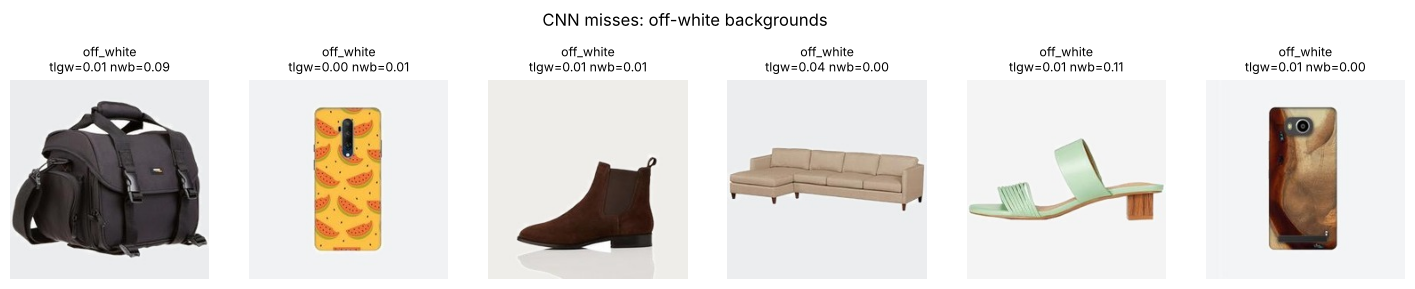

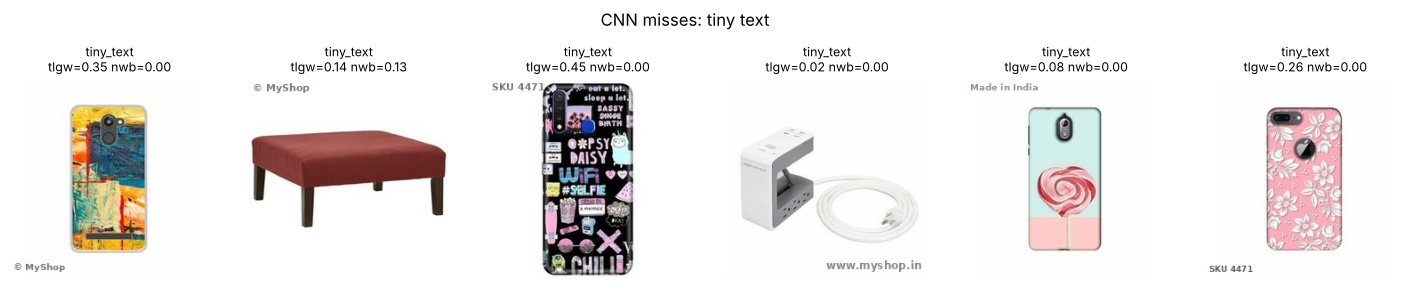

In [13]:
def show(df, title, cols=('tlgw_prob', 'nwb_prob'), n=6, folder='data/hard_test'):
    rows = df.sample(min(n, len(df)), random_state=0)
    if len(rows) == 0: print('nothing to show'); return
    fig, axes = plt.subplots(1, len(rows), figsize=(3 * len(rows), 3.5), squeeze=False)
    for ax, r in zip(axes[0], rows.itertuples()):
        ax.imshow(Image.open(f'{folder}/images/{r.file}'))
        ax.set_title(f'{r.detail}\n' + ' '.join(f'{c.split("_")[0]}={getattr(r, c):.2f}' for c in cols), fontsize=9); ax.axis('off')
    fig.suptitle(title); plt.show()

show(hmob[(hmob.detail == 'off_white') & (hmob.nwb_prob < th_f1['nwb'])], 'CNN misses: off-white backgrounds')
show(hmob[(hmob.detail == 'tiny_text') & (hmob.tlgw_prob < th_f1['tlgw'])], 'CNN misses: tiny text')

### How would we fix this?
1. **Better training data (the real fix).** Add off-white backgrounds and tiny text to `make_violations.py` and retrain. The model can only learn what it has seen.
2. **Combine methods.** Flag an image if *either* the CNN *or* the rule says NWB. Each catches what the other misses.
3. **Tune the rule.** Amazon wants *pure* white, so a stricter tolerance makes sense. Let's try a few:

In [14]:
from rules import white_border_fraction
rows = []
for tol in [12, 6, 3]:
    for name, df, folder in [('normal test', test, 'data/processed'), ('hard test', hmob, 'data/hard_test')]:
        frac_not_white = np.array([1 - white_border_fraction(Image.open(f'{folder}/images/{f}'), tol=tol) for f in df.file])
        m = label_metrics(df.nwb, (frac_not_white >= 0.2).astype(float))
        rows.append({'tol': tol, 'set': name, **{k: round(m[k], 3) for k in ['precision', 'recall', 'f1']}})
pd.DataFrame(rows).set_index(['tol', 'set'])

precision  recall     f1
tol set                                  
12  normal test      0.962    1.00  0.980
    hard test        0.929    0.65  0.765
6   normal test      0.946    1.00  0.972
    hard test        0.942    0.98  0.961
3   normal test      0.879    1.00  0.936
    hard test        0.800    1.00  0.889

`tol=6` catches almost all off-white backgrounds and keeps good precision on both sets. `tol=3` is too strict: JPEG compression noise
makes real white pixels look "not white", so false alarms go up.

⚠️ **Honesty check:** we picked `tol=6` *by looking at the hard test set*. That's the same mistake as tuning on test data!
To claim this number fairly, we'd need yet another fresh set of images that we haven't looked at. In real projects
you keep a final "hold-out" set locked away until the very end for exactly this reason.

## 7. Grad-CAM: where does the CNN look?
Red = "this region pushed the answer towards YES". We want TLGW to light up on the text, and NWB on the background.

I0000 00:00:1794909760.737158    2078 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794909760.737708    2078 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794909760.786570    2078 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794909762.115387    2078 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794909762.115970    2078 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1794909762.292668    2078 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


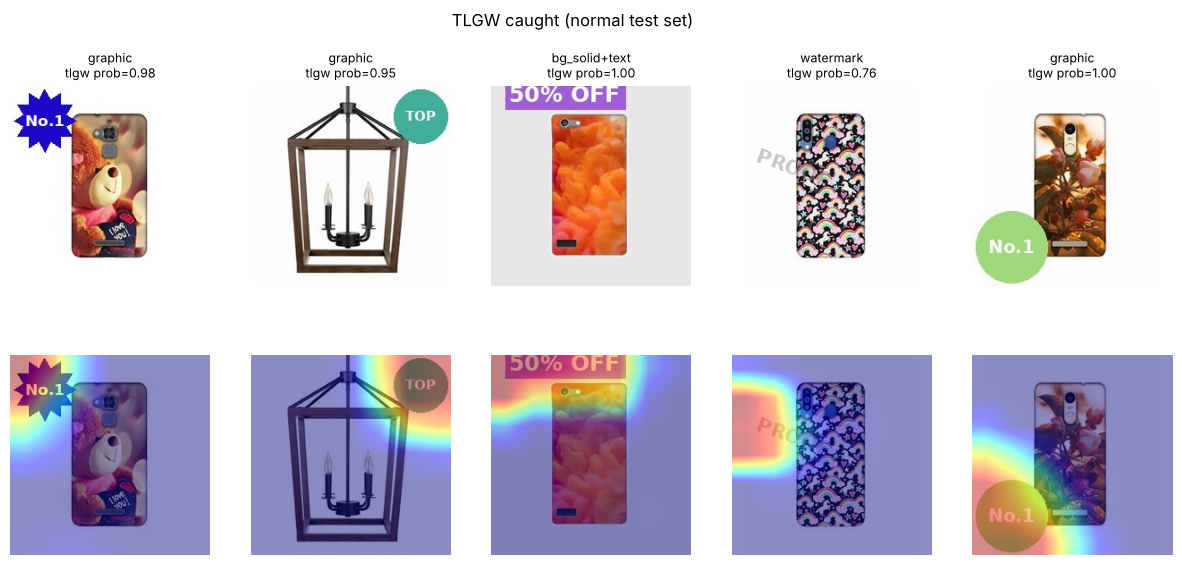

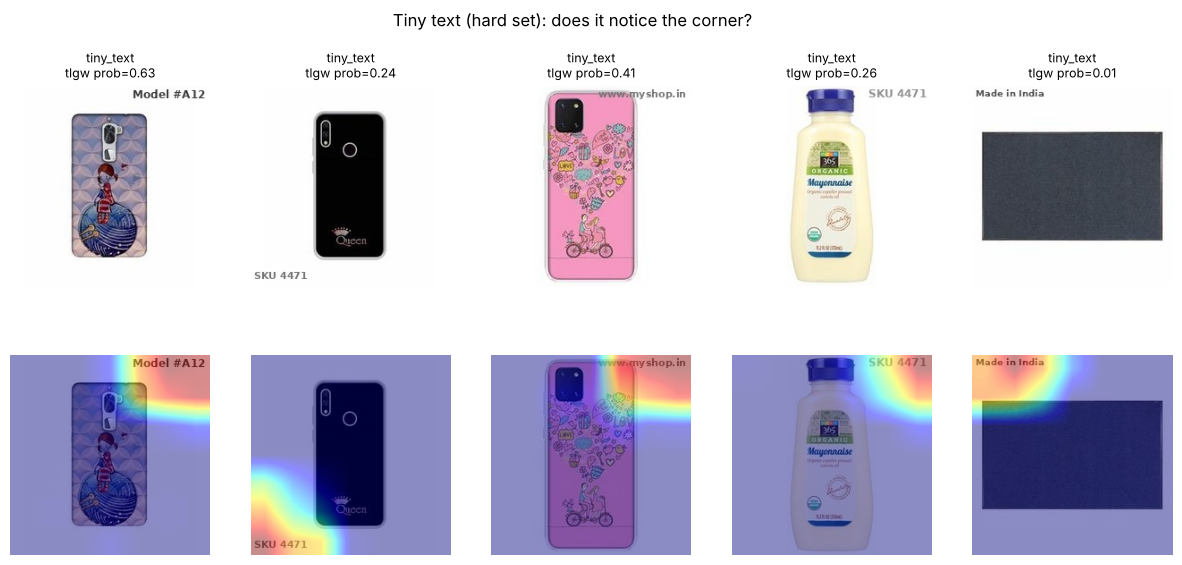

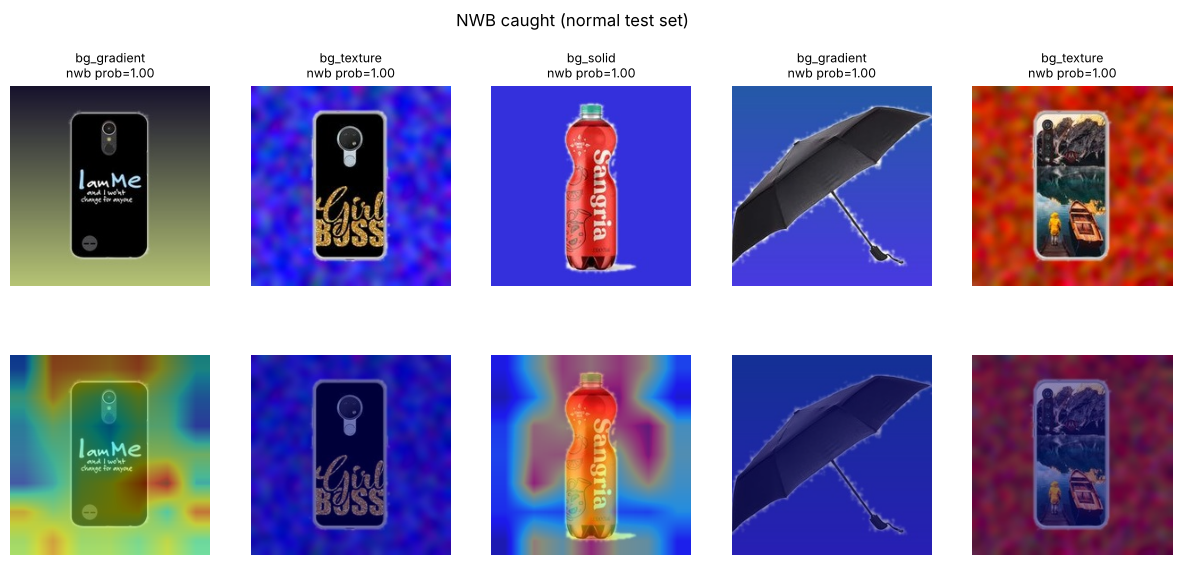

In [15]:
from tensorflow import keras
from gradcam import gradcam, overlay
model = keras.models.load_model('results/cnn_mobilenet.keras')

def cam_grid(df, label, title, folder, n=5):
    rows = df.sample(min(n, len(df)), random_state=1)
    if len(rows) == 0: print('nothing to show'); return
    fig, axes = plt.subplots(2, len(rows), figsize=(3 * len(rows), 6.4), squeeze=False)
    for k, r in enumerate(rows.itertuples()):
        img = Image.open(f'{folder}/images/{r.file}')
        p, cam = gradcam(model, img, label)
        axes[0, k].imshow(img); axes[0, k].set_title(f'{r.detail}\n{label} prob={p:.2f}', fontsize=9)
        axes[1, k].imshow(overlay(img, cam))
        for a in axes[:, k]: a.axis('off')
    fig.suptitle(title); plt.show()

cam_grid(test[(test.tlgw == 1) & (test.tlgw_prob >= 0.5)], 'tlgw', 'TLGW caught (normal test set)', 'data/processed')
cam_grid(hmob[hmob.detail == 'tiny_text'], 'tlgw', 'Tiny text (hard set): does it notice the corner?', 'data/hard_test')
cam_grid(test[(test.nwb == 1) & (test.tlgw == 0)], 'nwb', 'NWB caught (normal test set)', 'data/processed')

## Summary
| Lesson | What we saw |
|---|---|
| Accuracy can lie | "always no" scored about 67%; on the hard set the CNN's NWB accuracy looked fine while its recall collapsed |
| Use precision and recall per label | they show *which* mistake a model makes: false alarms or misses |
| Thresholds are a business choice | 98% recall for TLGW costs a lot of precision |
| Tune on validation, test once | and keep a final hold-out set, since tuning on test inflates scores |
| Test on realistic data | synthetic data that's too easy hides weaknesses |
| Look inside the model | Grad-CAM shows whether it looks at the right thing |

**Next, Step 4:** put the model behind a FastAPI endpoint (using `results/thresholds.json`), package it with Docker,
add GitHub Actions tests, and monitor how often each flag fires with Evidently.